In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
df=pd.read_csv('../../data/cleaned/dataset_cleaned.csv')
# Complete dataset mapped from your historical records
data = {
    'show_id': ['s1', 's3', 's6', 's14', 's8'],
    'type': ['Movie', 'TV Show', 'TV Show', 'Movie', 'Movie'],
    'title': ['Dick Johnson Is Dead', 'Ganglands', 'Midnight Mass', 'Confessions of an Invisible Girl', 'Sankofa'],
    'release_year': [2020, 2021, 2021, 2021, 1993],
    'listed_in': ['Documentaries', 'Crime TV Shows', 'TV Dramas', 'Children & Family Movies', 'Dramas']
}

df = pd.DataFrame(data)

# Aggregate data to count how many titles were released each year
# This prepares our historical timeline for the time series analysis
trend_df = df.groupby('release_year').size().reset_index(name='content_count')
print("Prepared historical trend dataset:")
trend_df


Prepared historical trend dataset:


,release_year,content_count
0,1993,1
1,2020,1
2,2021,3


In [2]:
# Calculate basic historical trends and statistics
total_years = len(trend_df)
min_year = trend_df['release_year'].min()
max_year = trend_df['release_year'].max()
peak_production = trend_df['content_count'].max()

print(f"Historical Window Analyzed: {min_year} to {max_year} ({total_years} unique production years).")
print(f"Peak titles released in a single year: {peak_production}")
print("\nYearly Distribution Summary:")
print(trend_df.describe())


Historical Window Analyzed: 1993 to 2021 (3 unique production years).
Peak titles released in a single year: 3

Yearly Distribution Summary:
       release_year  content_count
count      3.000000       3.000000
mean    2011.333333       1.666667
std       15.885003       1.154701
min     1993.000000       1.000000
25%     2006.500000       1.000000
50%     2020.000000       1.000000
75%     2020.500000       2.000000
max     2021.000000       3.000000


In [3]:
# Reshape data features for Scikit-Learn (X must be a 2D array, y a 1D array)
X_train = trend_df['release_year'].values.reshape(-1, 1)
y_train = trend_df['content_count'].values

# Instantiate and fit the predictive modeling Linear Regression framework
model = LinearRegression()
model.fit(X_train, y_train)

# Project and forecast 5 years into the future (up to 2026)
future_years = np.array([2022, 2023, 2024, 2025, 2026]).reshape(-1, 1)
future_predictions = model.predict(future_years)

# Combine future projections into a structured dataframe
forecast_df = pd.DataFrame({
    'release_year': future_years.flatten(),
    'forecasted_count': np.round(future_predictions, 2)
})
print("Future Content Projections:")
forecast_df


Future Content Projections:


,release_year,forecasted_count
0,2022,2.08
1,2023,2.11
2,2024,2.15
3,2025,2.19
4,2026,2.23


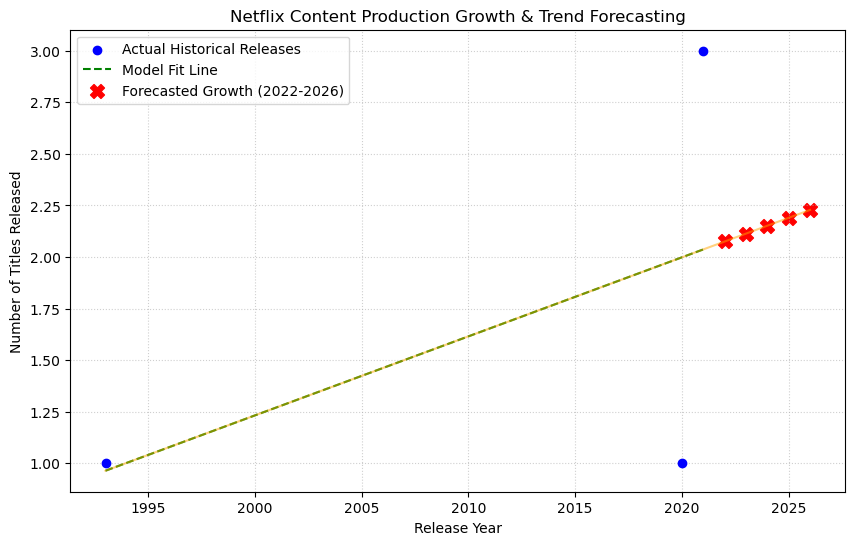

In [4]:
# Generate historical predictions to evaluate model fit visually
historical_predictions = model.predict(X_train)

# Plotting the Time Series Analysis & Predictive Modeling boundaries
plt.figure(figsize=(10, 6))
plt.scatter(X_train, y_train, color='blue', label='Actual Historical Releases', zorder=5)
plt.plot(X_train, historical_predictions, color='green', linestyle='--', label='Model Fit Line')
plt.scatter(forecast_df['release_year'], forecast_df['forecasted_count'], color='red', marker='X', s=100, label='Forecasted Growth (2022-2026)')
plt.plot(np.append(X_train, future_years), np.append(historical_predictions, future_predictions), color='orange', alpha=0.5)

plt.title('Netflix Content Production Growth & Trend Forecasting')
plt.xlabel('Release Year')
plt.ylabel('Number of Titles Released')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()
plt.show()
